In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import zipfile
import os

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

In [2]:
_URL = "https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip"

path_to_zip = tf.keras.utils.get_file(
    "cats_and_dogs.zip",
    origin=_URL,
    extract=False
)

zip_ref = zipfile.ZipFile(path_to_zip, "r")
zip_ref.extractall("/content")
zip_ref.close()

base_dir = "/content/cats_and_dogs_filtered"

train_dir = os.path.join(base_dir, "train")
validation_dir = os.path.join(base_dir, "validation")

68606236/68606236 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [3]:
IMG_SIZE = (150,150)
BATCH_SIZE = 32

train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    validation_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_dataset.class_names
print(class_names)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
['cats', 'dogs']


In [4]:
model = models.Sequential([

    layers.Rescaling(1./255, input_shape=(150,150,3)),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),

    layers.Dense(512, activation='relu'),

    layers.Dense(1, activation='sigmoid')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [6]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 180ms/step - accuracy: 0.5100 - loss: 0.6976 - val_accuracy: 0.5020 - val_loss: 0.6901
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.5715 - loss: 0.6758 - val_accuracy: 0.5800 - val_loss: 0.6703
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.6150 - loss: 0.6483 - val_accuracy: 0.6010 - val_loss: 0.6876
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.6565 - loss: 0.6208 - val_accuracy: 0.6740 - val_loss: 0.6105
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.7090 - loss: 0.5677 - val_accuracy: 0.6940 - val_loss: 0.5905
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.7395 - loss: 0.5270 - val_accuracy: 0.6940 - val_loss: 0.6013
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.7650 - loss: 0.4838 - val_accuracy: 0.7170 - val_loss: 0.5786
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.7820 - loss: 0.4441 - val_accuracy: 0.6970 -

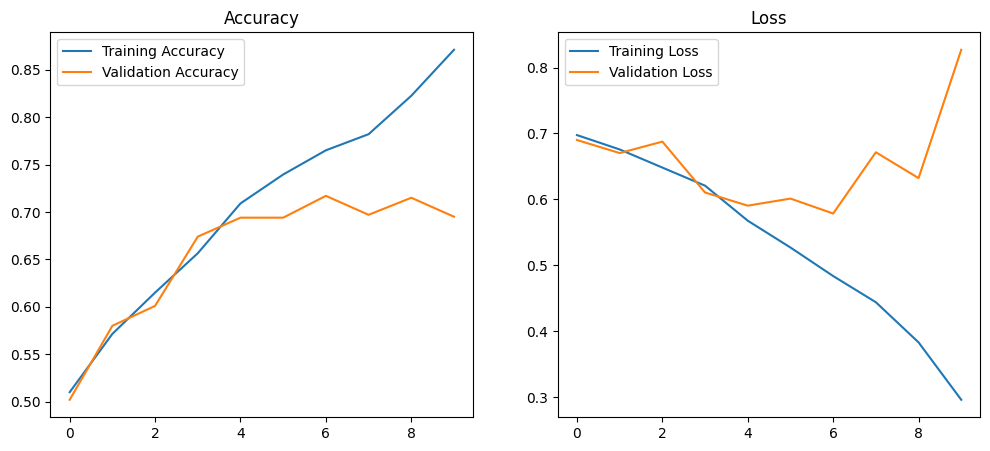

In [7]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()

In [8]:
y_true = []
y_pred_prob = []

for images, labels in validation_dataset:

    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred_prob.extend(predictions.flatten())

y_true = np.array(y_true)
y_pred_prob = np.array(y_pred_prob)

y_pred = (y_pred_prob > 0.5).astype(int)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=['Cat','Dog']
    )
)

              precision    recall  f1-score   support

         Cat       0.81      0.51      0.63       500
         Dog       0.64      0.88      0.74       500

    accuracy                           0.69      1000
   macro avg       0.73      0.70      0.68      1000
weighted avg       0.73      0.69      0.68      1000



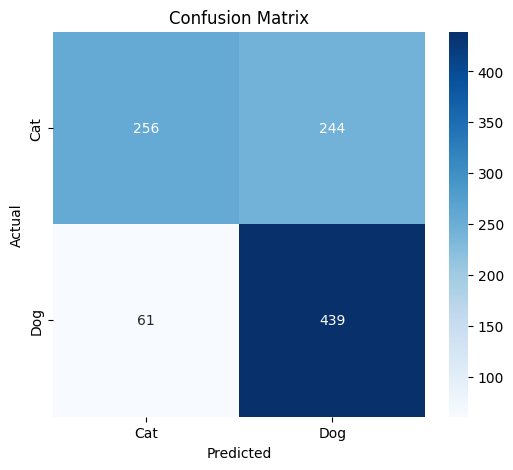

In [9]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Cat','Dog'],
    yticklabels=['Cat','Dog']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

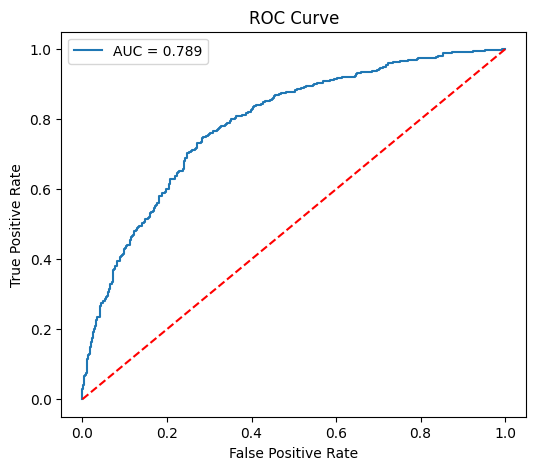

AUC Score: 0.7887200000000001


In [10]:
fpr, tpr, thresholds = roc_curve(
    y_true,
    y_pred_prob
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    'r--'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

print("AUC Score:", roc_auc)

In [ ]:
import urllib.request

# Download a sample cat image to use as test.jpg
url = 'https://upload.wikimedia.org/wikipedia/commons/3/3a/Cat03.jpg'
urllib.request.urlretrieve(url, '/content/test.jpg')
print('Downloaded sample image to /content/test.jpg')

In [15]:
import os
import shutil
import numpy as np
from tensorflow.keras.preprocessing import image

img_path = "/content/test.jpg"

# Instead of downloading externally, copy a sample cat image from the extracted dataset
if not os.path.exists(img_path):
    # Path to a validation cat image we already have locally
    local_sample = "/content/cats_and_dogs_filtered/validation/cats/cat.2000.jpg"
    if os.path.exists(local_sample):
        shutil.copy(local_sample, img_path)
        print("Copied sample cat image from local dataset to /content/test.jpg")
    else:
        raise FileNotFoundError("Could not find local sample image in extracted dataset.")

img = image.load_img(
    img_path,
    target_size=(150,150)
)

img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

prediction = model.predict(img_array)

if prediction[0][0] > 0.5:
    print("Predicted: Dog 🐶")
else:
    print("Predicted: Cat 🐱")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Predicted: Cat 🐱


In [14]:
model.save("cat_dog_classifier.h5")

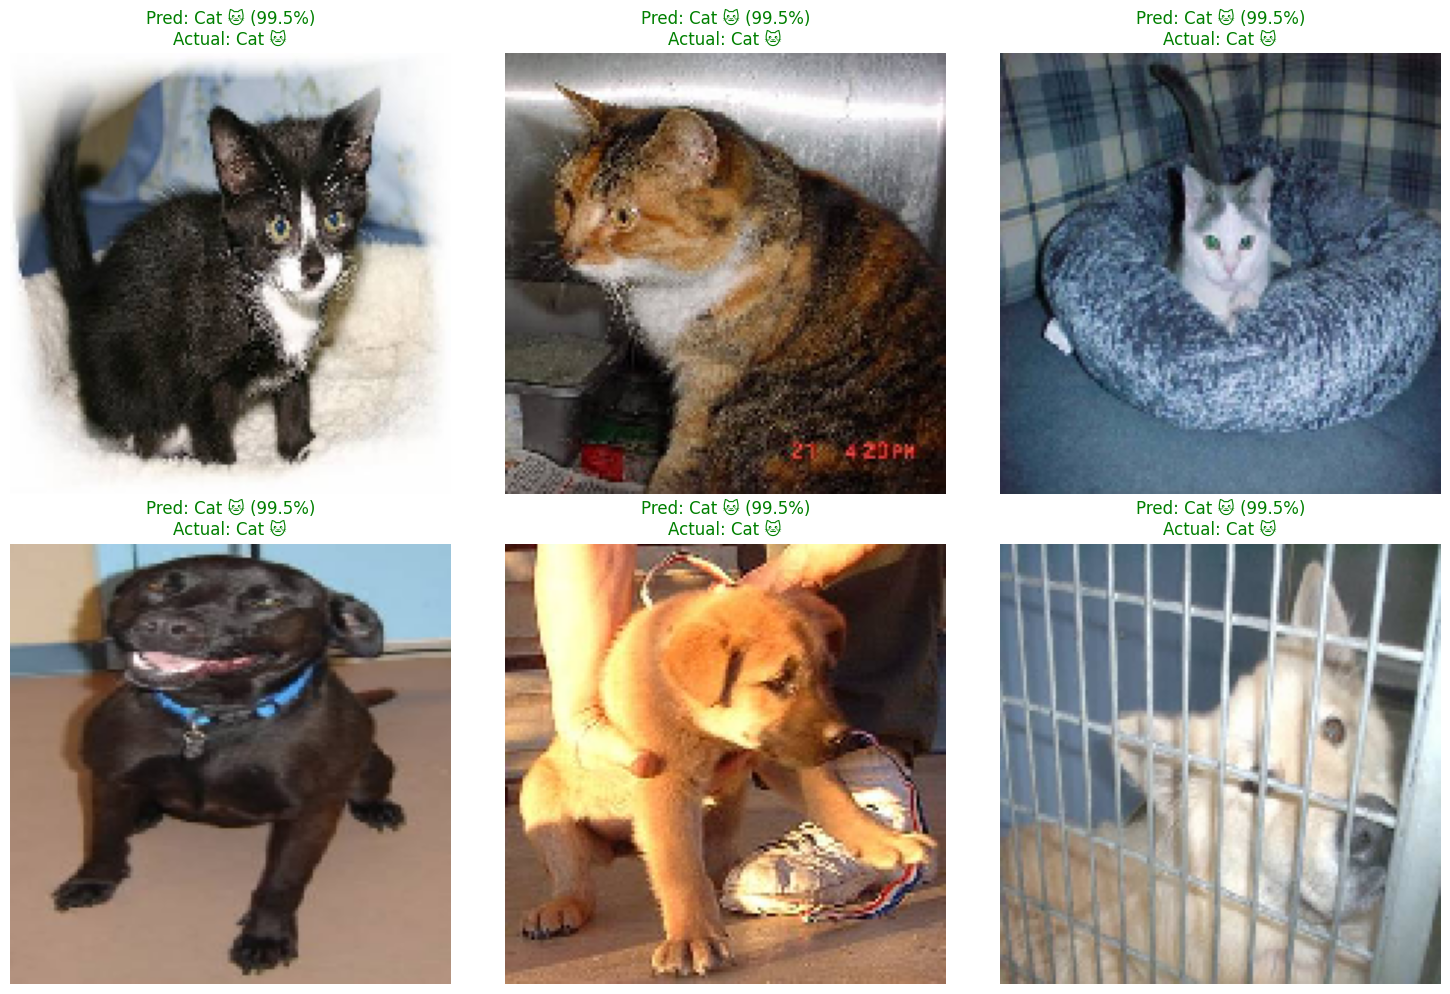

In [16]:
import os
import random
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing import image

# Define the paths to validation categories
validation_cats_dir = "/content/cats_and_dogs_filtered/validation/cats"
validation_dogs_dir = "/content/cats_and_dogs_filtered/validation/dogs"

# Get lists of image filenames
cat_fns = [os.path.join(validation_cats_dir, f) for f in os.listdir(validation_cats_dir) if f.endswith(('.jpg', '.jpeg', '.png'))]
dog_fns = [os.path.join(validation_dogs_dir, f) for f in os.listdir(validation_dogs_dir) if f.endswith(('.jpg', '.jpeg', '.png'))]

# Randomly pick 3 cats and 3 dogs
sample_cats = random.sample(cat_fns, 3)
sample_dogs = random.sample(dog_fns, 3)
test_samples = sample_cats + sample_dogs

# Plot configuration
plt.figure(figsize=(15, 10))

for i, img_path in enumerate(test_samples):
    # Load and preprocess the image
    img = image.load_img(img_path, target_size=(150, 150))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0

    # Model prediction
    prediction = model.predict(img_array, verbose=0)[0][0]
    predicted_class = "Dog 🐶" if prediction > 0.5 else "Cat 🐱"
    confidence = prediction if prediction > 0.5 else 1.0 - prediction

    # Determine actual label based on the folder path
    actual_class = "Cat 🐱" if "cats" in img_path else "Dog 🐶"

    # Plot image with details
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    color = "green" if predicted_class.split()[0] == actual_class.split()[0] else "red"
    plt.title(f"Pred: {predicted_class} ({confidence*100:.1f}%)\nActual: {actual_class}", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()